# LAB3 - Bài 2 (Trang 18 - 19): Gom cụm khách hàng Mall Customers bằng k-Means
**Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT**

In [1]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 1) Nhập dữ liệu, thống kê thông tin cơ bản, xử lý dữ liệu bị thiếu
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objs as go
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings; warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)

df = pd.read_csv("Mall_Customers.csv")
print("Kích thước dữ liệu:", df.shape)
print(df.head())
print()
df.info()
print("\nThống kê mô tả:")
print(df.describe())
print("\nSố giá trị thiếu mỗi cột:")
print(df.isnull().sum())

Đinh Nhật Huyền Nhân - 6451071055


Kích thước dữ liệu: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Thống kê mô tả:
       CustomerID         Age  

In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 1) Xử lý dữ liệu thiếu: số -> trung vị, phân loại -> giá trị xuất hiện nhiều nhất; bỏ dòng trùng
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])
df = df.drop_duplicates()
print("Số giá trị thiếu sau xử lý:", int(df.isnull().sum().sum()))
print("Kích thước sau xử lý:", df.shape)

Đinh Nhật Huyền Nhân - 6451071055
Số giá trị thiếu sau xử lý: 0
Kích thước sau xử lý: (200, 5)


Đinh Nhật Huyền Nhân - 6451071055


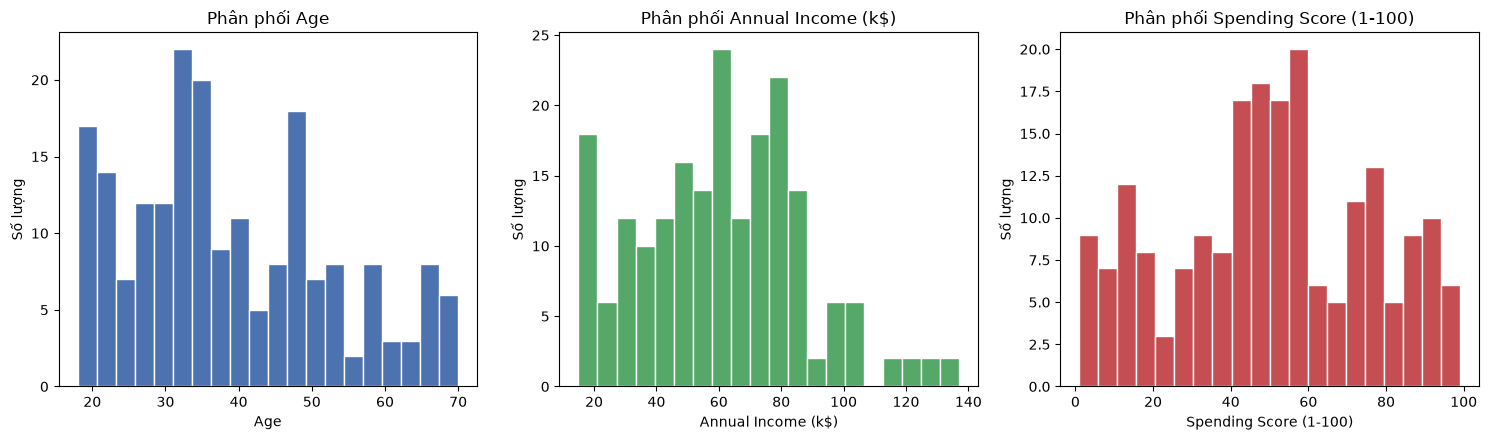

In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 2) Histogram phân phối Tuổi, Thu nhập hằng năm, Số điểm mua sắm
plt.figure(figsize=(15, 4.5))
for i, col in enumerate(["Age", "Annual Income (k$)", "Spending Score (1-100)"], start=1):
    plt.subplot(1, 3, i)
    plt.hist(df[col], bins=20, color=["#4C72B0", "#55A868", "#C44E52"][i - 1], edgecolor="white")
    plt.title(f"Phân phối {col}"); plt.xlabel(col); plt.ylabel("Số lượng")
plt.tight_layout(); plt.show()

Đinh Nhật Huyền Nhân - 6451071055
Gender
Female    112
Male       88
Name: count, dtype: int64


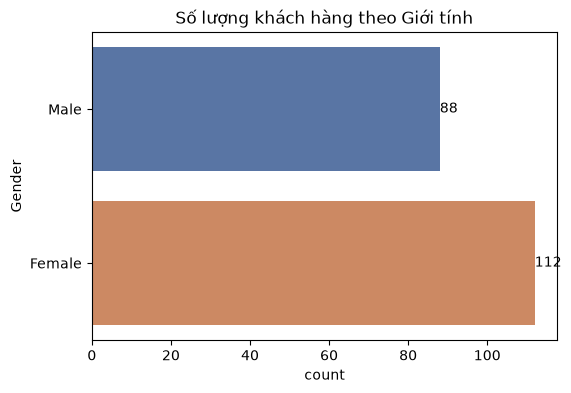

In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 3) Thống kê số mẫu theo Giới tính
print(df["Gender"].value_counts())
plt.figure(figsize=(6, 4))
ax = sns.countplot(y="Gender", data=df, palette=["#4C72B0", "#DD8452"])
for c in ax.containers: ax.bar_label(c)
plt.title("Số lượng khách hàng theo Giới tính"); plt.show()

Đinh Nhật Huyền Nhân - 6451071055


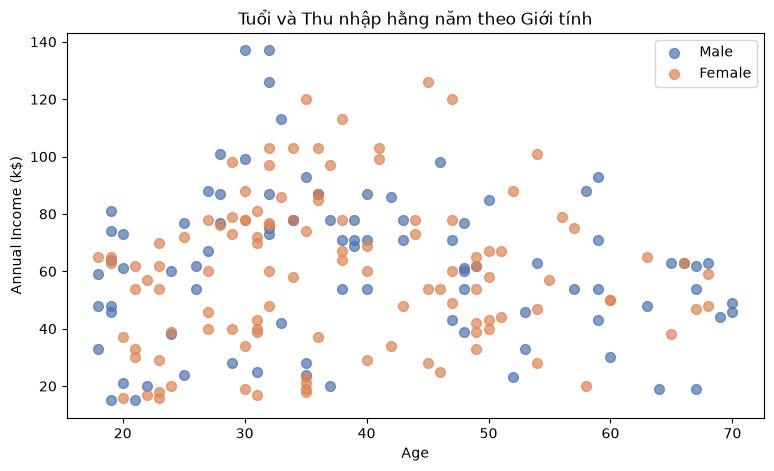

In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 4) Scatter: Tuổi và Thu nhập hằng năm theo Giới tính
plt.figure(figsize=(9, 5))
for g, c in [("Male", "#4C72B0"), ("Female", "#DD8452")]:
    d = df[df["Gender"] == g]
    plt.scatter(d["Age"], d["Annual Income (k$)"], s=50, alpha=0.7, c=c, label=g)
plt.xlabel("Age"); plt.ylabel("Annual Income (k$)"); plt.legend()
plt.title("Tuổi và Thu nhập hằng năm theo Giới tính"); plt.show()

Đinh Nhật Huyền Nhân - 6451071055


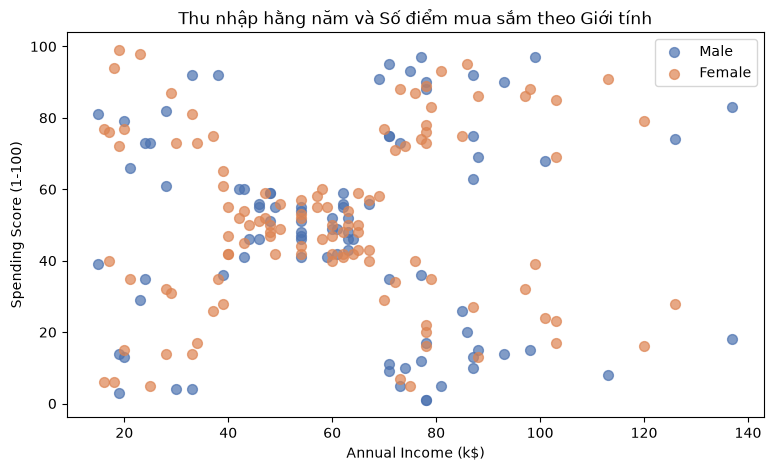

In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 5) Scatter: Thu nhập hằng năm và Số điểm mua sắm theo Giới tính
plt.figure(figsize=(9, 5))
for g, c in [("Male", "#4C72B0"), ("Female", "#DD8452")]:
    d = df[df["Gender"] == g]
    plt.scatter(d["Annual Income (k$)"], d["Spending Score (1-100)"], s=50, alpha=0.7, c=c, label=g)
plt.xlabel("Annual Income (k$)"); plt.ylabel("Spending Score (1-100)"); plt.legend()
plt.title("Thu nhập hằng năm và Số điểm mua sắm theo Giới tính"); plt.show()

Đinh Nhật Huyền Nhân - 6451071055


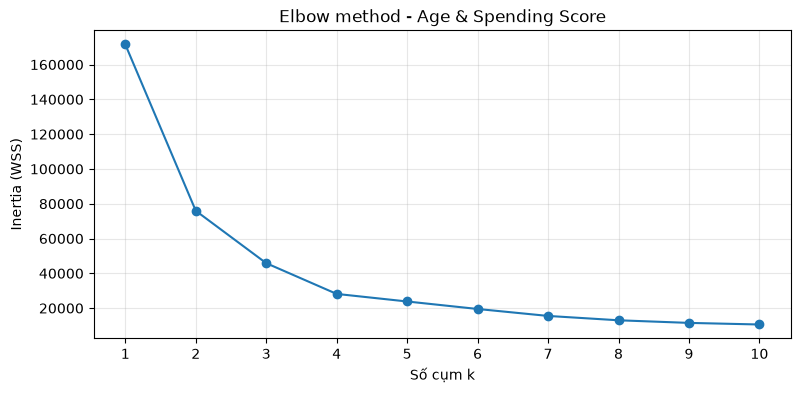

k =  1: WSS = 171,535.50
k =  2: WSS = 75,949.16
k =  3: WSS = 45,840.68
k =  4: WSS = 28,165.58
k =  5: WSS = 23,818.85
k =  6: WSS = 19,510.33
k =  7: WSS = 15,514.19
k =  8: WSS = 13,012.80
k =  9: WSS = 11,513.13
k = 10: WSS = 10,590.81


In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 6) Elbow method cho cặp thuộc tính Tuổi - Số điểm mua sắm
def elbow(X, tieu_de, k_max=10):
    inertia = []
    for k in range(1, k_max + 1):
        km = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=111)
        km.fit(X)
        inertia.append(km.inertia_)
    plt.figure(figsize=(9, 4))
    plt.plot(range(1, k_max + 1), inertia, "o-", color="tab:blue")
    plt.xticks(range(1, k_max + 1)); plt.xlabel("Số cụm k"); plt.ylabel("Inertia (WSS)")
    plt.title(f"Elbow method - {tieu_de}"); plt.grid(alpha=0.3); plt.show()
    for k, v in zip(range(1, k_max + 1), inertia):
        print(f"k = {k:2d}: WSS = {v:,.2f}")
    return inertia

X1 = df[["Age", "Spending Score (1-100)"]].values
inertia1 = elbow(X1, "Age & Spending Score")

In [8]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 6) Từ biểu đồ elbow chọn k = 4 và gom cụm bằng k-Means
km1 = KMeans(n_clusters=4, init="k-means++", n_init=10, max_iter=300, random_state=111)
labels1 = km1.fit_predict(X1)
centroids1 = km1.cluster_centers_
print("Tâm các cụm (Age, Spending Score):\n", np.round(centroids1, 2))
print("Số khách hàng mỗi cụm:", np.bincount(labels1))

Đinh Nhật Huyền Nhân - 6451071055
Tâm các cụm (Age, Spending Score):
 [[27.62 49.15]
 [30.18 82.35]
 [55.71 48.23]
 [43.29 15.02]]
Số khách hàng mỗi cụm: [47 57 48 48]


Đinh Nhật Huyền Nhân - 6451071055


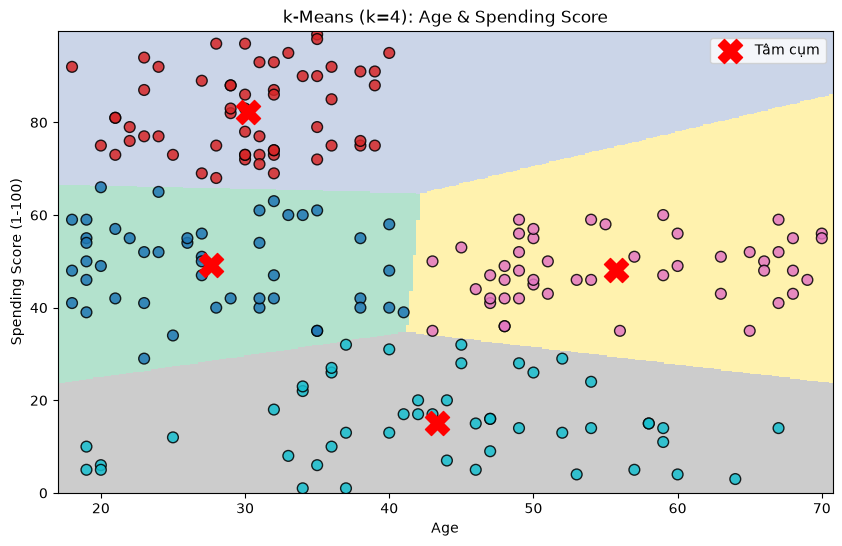

In [9]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 7) Biểu diễn kết quả gom cụm (vùng quyết định + điểm dữ liệu + tâm cụm)
def ve_cum_2d(X, labels, km, xlab, ylab, tieu_de):
    h = 0.25
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = km.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(10, 6))
    plt.imshow(Z, interpolation="nearest", extent=(xx.min(), xx.max(), yy.min(), yy.max()),
               cmap=plt.cm.Pastel2, aspect="auto", origin="lower")
    plt.scatter(X[:, 0], X[:, 1], c=labels, s=60, cmap="tab10", edgecolor="k", alpha=0.85)
    plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], s=300, c="red", marker="X", label="Tâm cụm")
    plt.xlabel(xlab); plt.ylabel(ylab); plt.title(tieu_de); plt.legend(); plt.show()

ve_cum_2d(X1, labels1, km1, "Age", "Spending Score (1-100)", "k-Means (k=4): Age & Spending Score")

In [10]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 8) Đánh giá bằng hệ số dáng điệu (Silhouette coefficient)
s1 = silhouette_score(X1, labels1)
print(f"Silhouette (Age & Spending Score, k=4) = {s1:.4f}")

Đinh Nhật Huyền Nhân - 6451071055
Silhouette (Age & Spending Score, k=4) = 0.4997


Đinh Nhật Huyền Nhân - 6451071055


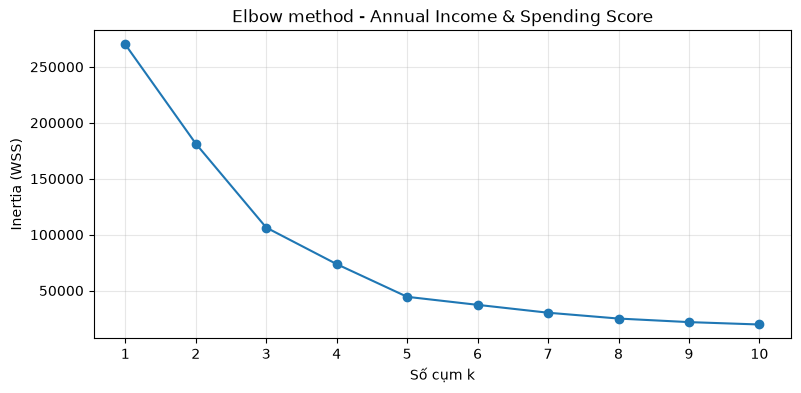

k =  1: WSS = 269,981.28
k =  2: WSS = 181,363.60
k =  3: WSS = 106,348.37
k =  4: WSS = 73,679.79
k =  5: WSS = 44,448.46
k =  6: WSS = 37,265.87
k =  7: WSS = 30,241.34
k =  8: WSS = 25,022.49
k =  9: WSS = 21,841.98
k = 10: WSS = 19,707.26


In [11]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 9.1) Thu nhập hằng năm và Số điểm mua sắm: Elbow
X2 = df[["Annual Income (k$)", "Spending Score (1-100)"]].values
inertia2 = elbow(X2, "Annual Income & Spending Score")

Đinh Nhật Huyền Nhân - 6451071055
Tâm các cụm (Annual Income, Spending Score):
 [[86.54 82.13]
 [25.73 79.36]
 [88.2  17.11]
 [26.3  20.91]
 [55.3  49.52]]
Số khách hàng mỗi cụm: [39 22 35 23 81]


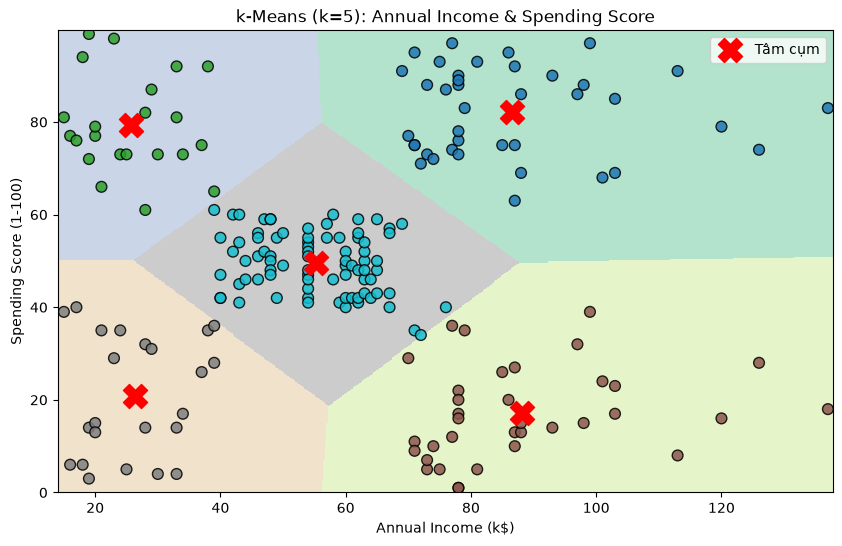

Silhouette (Annual Income & Spending Score, k=5) = 0.5539


In [12]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 9.1) Chọn k = 5, gom cụm, biểu diễn và tính Silhouette
km2 = KMeans(n_clusters=5, init="k-means++", n_init=10, max_iter=300, random_state=111)
labels2 = km2.fit_predict(X2)
print("Tâm các cụm (Annual Income, Spending Score):\n", np.round(km2.cluster_centers_, 2))
print("Số khách hàng mỗi cụm:", np.bincount(labels2))
ve_cum_2d(X2, labels2, km2, "Annual Income (k$)", "Spending Score (1-100)",
          "k-Means (k=5): Annual Income & Spending Score")
print(f"Silhouette (Annual Income & Spending Score, k=5) = {silhouette_score(X2, labels2):.4f}")

Đinh Nhật Huyền Nhân - 6451071055


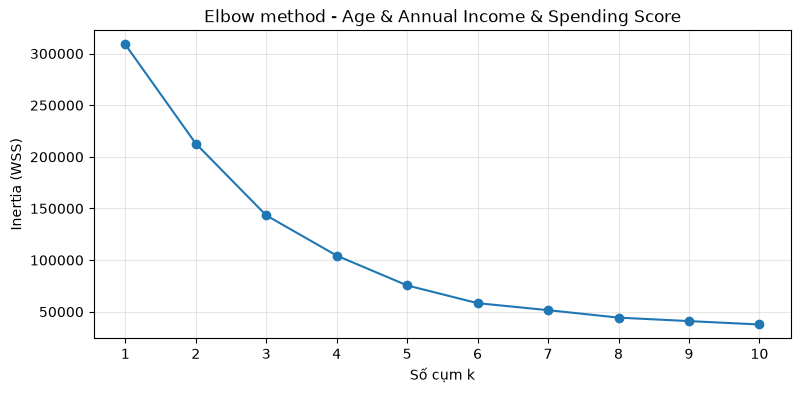

k =  1: WSS = 308,812.78
k =  2: WSS = 212,840.17
k =  3: WSS = 143,342.75
k =  4: WSS = 104,366.15
k =  5: WSS = 75,479.76
k =  6: WSS = 58,300.44
k =  7: WSS = 51,525.77
k =  8: WSS = 44,307.87
k =  9: WSS = 40,932.63
k = 10: WSS = 37,639.72


In [13]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 9.2) Tuổi, Thu nhập hằng năm và Số điểm mua sắm: Elbow
X3 = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].values
inertia3 = elbow(X3, "Age & Annual Income & Spending Score")

In [14]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 9.2) Chọn k = 6, gom cụm và tính Silhouette
km3 = KMeans(n_clusters=6, init="k-means++", n_init=10, max_iter=300, random_state=111)
labels3 = km3.fit_predict(X3)
df["cluster3"] = labels3
print("Tâm các cụm (Age, Annual Income, Spending Score):\n", np.round(km3.cluster_centers_, 2))
print("Số khách hàng mỗi cụm:", np.bincount(labels3))
print(f"Silhouette (Age & Annual Income & Spending Score, k=6) = {silhouette_score(X3, labels3):.4f}")

Đinh Nhật Huyền Nhân - 6451071055
Tâm các cụm (Age, Annual Income, Spending Score):
 [[41.69 88.23 17.29]
 [56.16 53.38 49.09]
 [32.69 86.54 82.13]
 [27.   56.66 49.13]
 [44.14 25.14 19.52]
 [25.27 25.73 79.36]]
Số khách hàng mỗi cụm: [35 45 39 38 21 22]
Silhouette (Age & Annual Income & Spending Score, k=6) = 0.4523


Đinh Nhật Huyền Nhân - 6451071055


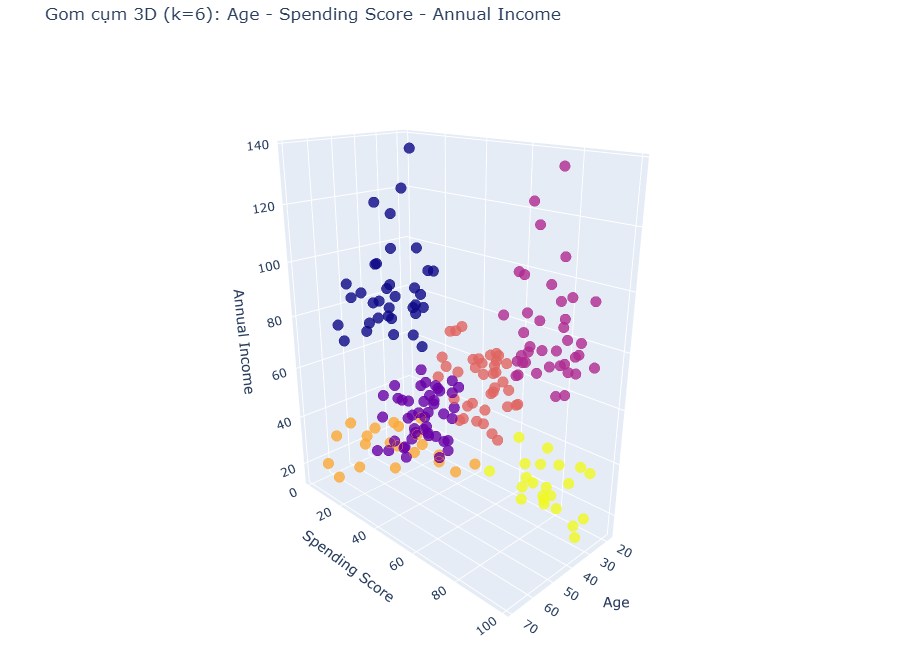

In [15]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# 9.2) Biểu đồ 3D kết quả gom cụm bằng plotly
trace = go.Scatter3d(
    x=df["Age"], y=df["Spending Score (1-100)"], z=df["Annual Income (k$)"], mode="markers",
    marker=dict(color=df["cluster3"], size=6, line=dict(color=df["cluster3"], width=10), opacity=0.8))
layout = go.Layout(title="Gom cụm 3D (k=6): Age - Spending Score - Annual Income",
                   width=900, height=650, margin=dict(l=0, r=0, b=0, t=40),
                   scene=dict(xaxis=dict(title="Age"), yaxis=dict(title="Spending Score"),
                              zaxis=dict(title="Annual Income"),
                              camera=dict(eye=dict(x=1.8, y=1.8, z=1.0))))
fig = go.Figure(data=[trace], layout=layout)
fig.write_html("mall_3d_clusters.html")      # bản tương tác
fig.show(renderer="png")                     # ảnh tĩnh để hiển thị trong notebook/báo cáo

- Khi gom theo Tuổi và Số điểm mua sắm (k=4), Silhouette ≈ 0.500. Các nhóm thu được: khách trẻ chi tiêu cao, khách trẻ chi tiêu trung bình, khách lớn tuổi chi tiêu trung bình, và khách trung niên chi tiêu thấp.
- Khi gom theo Thu nhập hằng năm và Số điểm mua sắm (k=5), Silhouette ≈ 0.554, cao nhất trong ba cách. Năm nhóm tách rất rõ: thu nhập cao - chi tiêu cao (nhóm khách hàng mục tiêu), thu nhập cao - chi tiêu thấp, thu nhập thấp - chi tiêu cao, thu nhập thấp - chi tiêu thấp, và nhóm trung bình.
- Khi gom theo cả ba thuộc tính (k=6), Silhouette ≈ 0.452: phân nhóm chi tiết hơn (tách nhóm trung bình theo độ tuổi) nhưng các cụm kém tách biệt hơn trong không gian 3 chiều.
- Cặp thuộc tính Thu nhập - Số điểm mua sắm cho kết quả gom cụm tốt và dễ diễn giải nhất cho mục đích phân khúc khách hàng.